# Городская экономика: Кластеризация экономических условий с помощью K-Means в 48 городах мира (1991)

## **1. Вступление**

В ходе анализа были проанализированы экономические условия в 48 городах по всему миру в 1991 году с использованием методов статистического анализа и машинного обучения.

Набор данных, собранный отделом экономических исследований Union Bank (Швейцария), содержит информацию о времени работы, ценах на товары и услуги, а также зарплатах в разных городах.

Основными используемыми статистическими методами являются ** Кластеризация по K-среднему значению:**, которые классифицируют города на группы со схожими экономическими характеристиками.
Анализ включает в себя:-
- описательную статистику и корреляционный анализ,
- выделение факторов и кластеризацию,
- графическую визуализацию и интерпретацию результатов.

Поскольку набор данных содержит три числовые переменные: работа, цена и зарплата. Таким образом, можно провести факторный анализ, чтобы исследовать взаимосвязи между экономическими переменными и выявить основные закономерности в экономических условиях городов.

## **2. Название работы**
**K-означает "Кластеризация глобальных экономических условий в городах в 1991 году"**

## **3. Цель работы**

Основная цель анализа - изучить и классифицировать экономические условия городов с использованием метода кластеризации по K-средним значениям.

Конкретными задачами являются:

1. Изучить структуру и качество набора данных.
2. Рассчитать описательную статистику для работы, цен и заработной платы.
3. Изучить взаимосвязи между экономическими показателями.
4. Стандартизировать числовые переменные.
5. Определить подходящее количество кластеров.
6. Сгруппировать города в соответствии с их экономическим сходством.
7. Визуализировать и интерпретировать полученные в результате городские кластеры.

## **4. Гипотеза**

Использовались две гипотезы.

H1: Существует значительная взаимосвязь между продолжительностью рабочего дня, ценами и заработной платой в 48 городах.

H2: Три экономических показателя могут иметь общий базовый аспект, отражающий различия в экономических условиях городов.

Кластеризация с использованием K-средних используется для проверки того, могут ли эти группы быть идентифицированы на основе данных.

Гипотеза будет проверена с использованием профилей кластеров и визуализаций.

## Описание набора данных

Набор данных содержит информацию о 48 городах по всему миру за 1991 год.

Переменными являются:

**Город** - это название города.
**Работа** - средневзвешенное количество рабочих часов по 12 профессиям.
**Цена** - это индекс цен на 112 товаров и услуг, включая арендную плату.
**Зарплата** Индекс почасовой оплаты труда после уплаты налогов по 12 профессиям

В качестве базового города для индексов цен и зарплат используется Цюрих, значение которого равно 100.
Переменная "Город" идентифицирует каждое наблюдение. 
Числовые переменные "Работа", "Цена" и "Зарплата" используются в анализе K-средних.

## Процесс
## Импорт библиотек Python

Первым шагом является импорт библиотек Python, необходимых для анализа и визуализации данных.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import (
    calculate_bartlett_sphericity,
    calculate_kmo
)

import warnings
warnings.filterwarnings("ignore")

# Set graph appearance
sns.set_theme(style="whitegrid")

# Reproducibility
np.random.seed(42)

print("All libraries imported successfully.")

All libraries imported successfully.


## Загрузите набор данных (Dataset loading)

Набор данных импортируется во фрейм данных Pandas.
Файл содержит названия городов и три числовых показателя. 
При первой проверке проверяется количество наблюдений, названия столбцов и типы данных.

In [2]:
df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")

# Checking dataset demensions
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

print("\nColumn names:", df.columns.tolist())

print("\nDataset information:")
df.info()

Number of observations: 48
Number of variables: 4

Column names: ['City', 'Work', 'Price', 'Salary']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     str    
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 1.6 KB


## Проверка и подготовка данных (Data Inspection and Preparations)

Перед применением K-средних необходимо проверить набор данных, не содержит ли он пропущенных значений, повторяющихся наблюдений или неверных типов данных.

При анализе в качестве числовых переменных используются **Работа**, **Цена** и **Зарплата**.
Значение -9999 рассматривается как код с пропущенным значением там, где оно появляется. 
Строки без полных значений для всех трех числовых переменных исключаются из анализа кластеризации.
Столбец "Город" сохраняется, чтобы результирующие кластеры можно было интерпретировать по названию города.

In [3]:
# Data cleaning
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove spaces from city names
df["City"] = df["City"].astype(str).str.strip()

# Convert economic variables into numerical format
variables = ["Work", "Price", "Salary"]

for col in variables:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate observations
print("\nDuplicate rows:", df.duplicated().sum())

# Remove rows with missing required values
df = df.dropna(subset=["City"] + variables).copy()

# Remove duplicate city observations
df = df.drop_duplicates(subset="City").reset_index(drop=True)

print("\nFinal dataset shape:", df.shape)

Missing values:
City      0
Work      0
Price     0
Salary    0
dtype: int64

Duplicate rows: 0

Final dataset shape: (48, 4)


### Набор данных (Dataset)
После очистки набор данных должен содержать 48 городов.
Если итоговое число меньше, проверьте отсутствующие или дублирующиеся записи, прежде чем продолжить.
Пропущенные значения не рассматриваются как реальные экономические показатели. 
В модель K-средних включены только города с полными значениями для работы, цены и заработной платы.

## Описательная статистика (Descriptive Statistics)

Описательная статистика рассчитывается для понимания распределения экономических показателей.

Анализ включает в себя:-
    - Среднее значение.
    - Стандартное отклонение. Вариации между городами.
    - Минимальное значение.
    - Максимальное значение.
    - Медиана. Среднее наблюдение (квартили).

Эти статистические данные дают общее представление о различиях в продолжительности рабочего дня, ценах и заработной плате в разных городах.

In [4]:
# Calculate descriptive statistics
descriptive = df[variables].describe().T

descriptive["median"] = df[variables].median()
descriptive["variance"] = df[variables].var()

print(descriptive.round(2))

        count     mean      std     min      25%     50%      75%     max  \
Work     48.0  1384.96  2404.90 -9999.0  1740.75  1834.5  1972.75  2375.0   
Price    48.0    68.86    21.78    30.3    49.65    70.5    81.70   115.5   
Salary   48.0  -378.73  2027.34 -9999.0    12.25    40.3    58.70   100.0   

        median    variance  
Work    1834.5  5783529.62  
Price     70.5      474.57  
Salary    40.3  4110099.58  


Описательная статистика показывает основные значения и вариации трех экономических показателей.

Среднее значение представляет собой среднее значение по городам. Стандартное отклонение показывает, насколько сильно наблюдения отличаются от среднего значения. Минимальное и максимальное значения указывают на самые низкие и самые высокие показатели.

Эти статистические данные помогают выявить экономические различия перед применением кластеризации.

Например:
- Более высокие показатели работы указывают на увеличение средней продолжительности рабочего дня.
- Более высокие значения цен указывают на более дорогую корзину товаров и услуг.
- Более высокие значения заработной платы указывают на более высокие показатели почасовой оплаты труда по сравнению с Цюрихом.

## Распределение экономических показателей (Distribution of Economic Indicators)

Гистограммы используются для изучения распределения работы, цен и заработной платы.

Они показывают, как часто встречаются различные значения, и помогают выявить возможные асимметрии или необычные наблюдения.

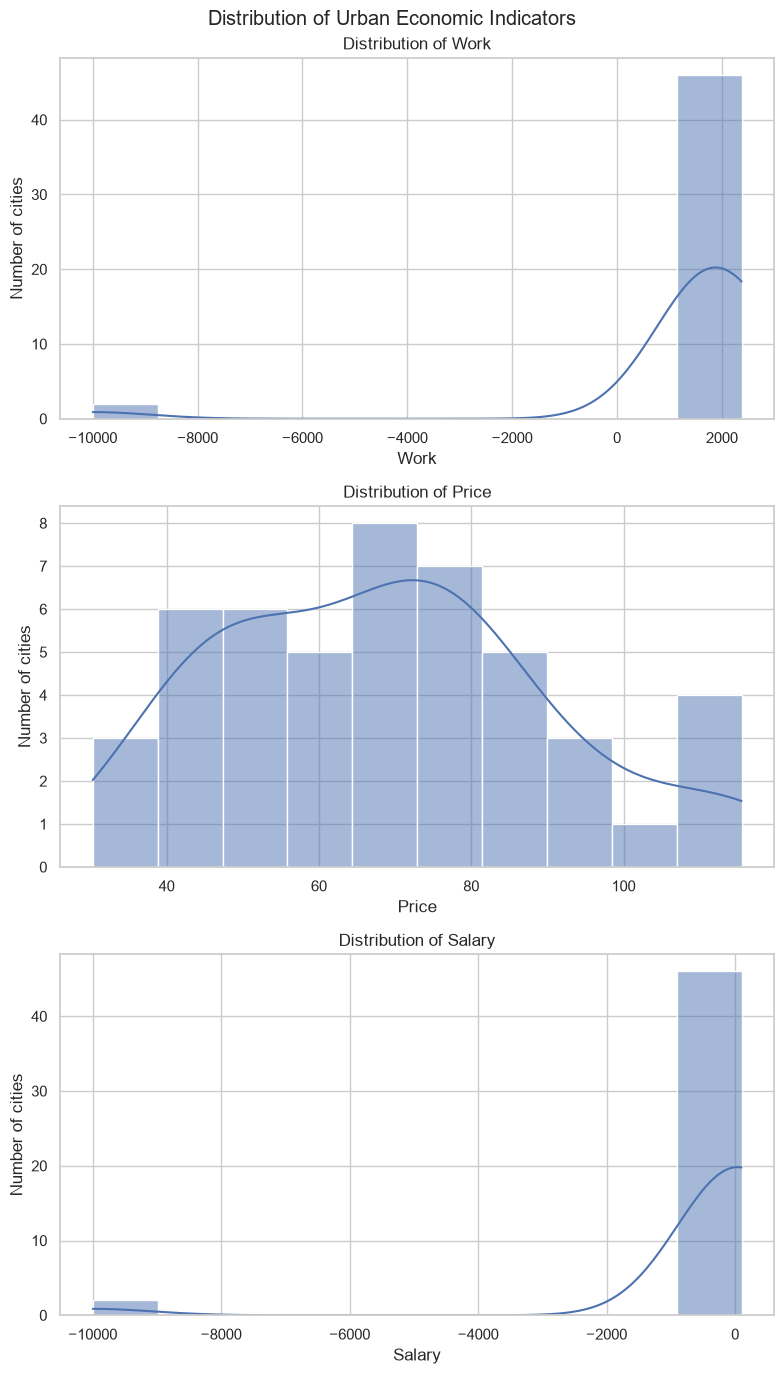

In [5]:
# Visulization
# Histograms
fig, axes = plt.subplots(3, 1, figsize=(8, 14))

for i, col in enumerate(variables):
    sns.histplot(df[col], kde=True, bins=10, ax=axes[i])

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of cities")

plt.suptitle("Distribution of Urban Economic Indicators")
plt.tight_layout()
plt.show()

Гистограммы показывают частотное распределение каждого экономического показателя. На графиках показаны медиана, разброс и возможные экстремальные значения.

Переменные измеряются в разных масштабах, поэтому их исходные значения не следует использовать непосредственно в K-средних. Поэтому требуется стандартизация.

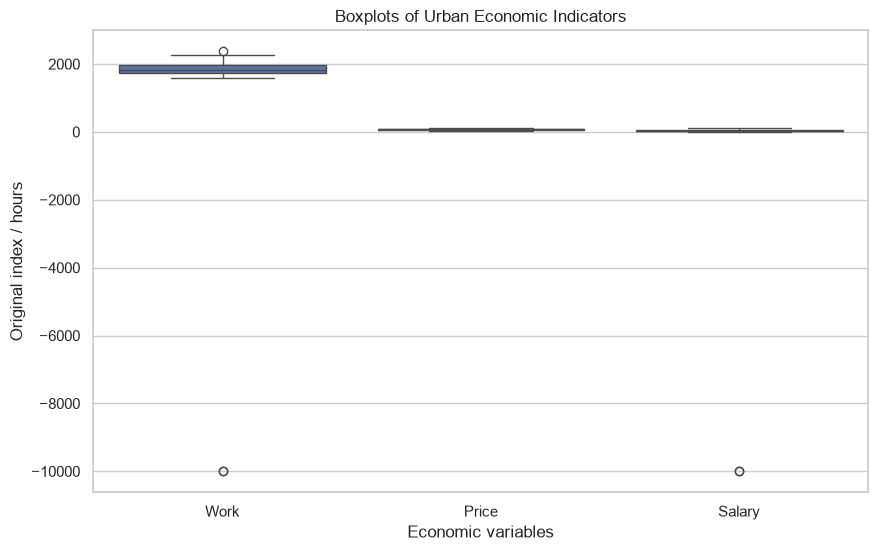

In [6]:
# Boxplots
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[variables])

plt.title("Boxplots of Urban Economic Indicators")
plt.ylabel("Original index / hours")
plt.xlabel("Economic variables")

plt.show()

 На графиках (The boxplots) показаны медиана, разброс и возможные экстремальные значения.

## Корреляционный анализ (Correlation Analysis)

Корреляционный анализ исследует направление и силу линейных зависимостей между работой, ценой и заработной платой.

Коэффициент корреляции варьируется от -1 до +1.

 Положительное значение указывает на то, что две переменные имеют тенденцию к увеличению.
      (Близко к +1 указывает на сильную положительную взаимосвязь)
- Отрицательное значение указывает на то, что одна переменная имеет тенденцию к уменьшению при увеличении другой.
      (Значение, близкое к -1, указывает на сильную отрицательную взаимосвязь).
- Значение, близкое к нулю, указывает на слабую линейную взаимосвязь.
      (Значение, близкое к 0, указывает на слабую линейную взаимосвязь).

Корреляция используется здесь для предварительного описания. Она не устанавливает причинно-следственную связь.

In [7]:
# Correlation analysis
# Calculate correlation matrix
corr_matrix = df[variables].corr(method="pearson")

print("\nCorrelation Matrix:\n")
print(corr_matrix.round(3))


Correlation Matrix:

         Work  Price  Salary
Work    1.000  0.244   0.997
Price   0.244  1.000   0.285
Salary  0.997  0.285   1.000


Корреляционная матрица показывает (The correlation matrix indicates), как экономические показатели связаны друг с другом.
Положительная корреляция между ценой и заработной платой указывает на то, что города с более высокими индексами цен, как правило, имеют более высокие индексы заработной платы.
Отрицательная корреляция между работой и другой переменной указывает на то, что в городах с более продолжительным рабочим днем, как правило, значения этой переменной ниже.
Эти взаимосвязи носят описательный характер и не подразумевают, что одна переменная влияет на другую.

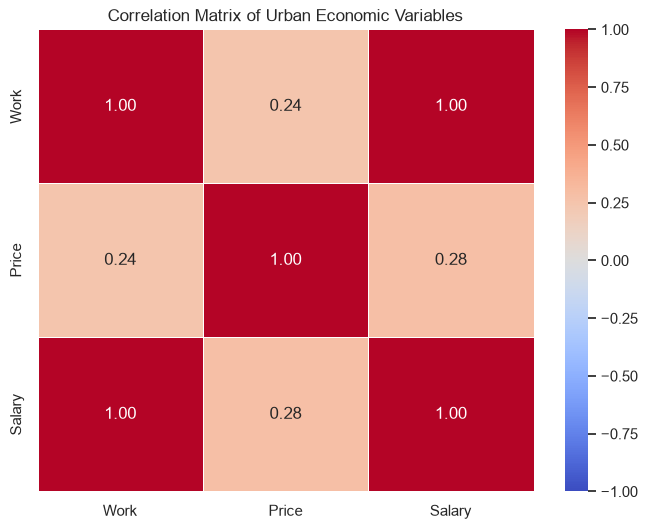

In [8]:
# Correlation heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title("Correlation Matrix of Urban Economic Variables")
plt.show()


**Тепловая карта**(The heatmap makes) облегчает понимание взаимосвязей между переменными.

Например:
- Положительная корреляция цены и заработной платы указывает на то, что города с более высокими показателями заработной платы, как правило, имеют более высокие индексы цен.
- Отрицательная корреляция между работой и зарплатой указывает на то, что в городах с более высокими зарплатами, как правило, сокращается продолжительность рабочего дня.
- Слабая корреляция указывает на то, что эти два показателя не имеют сильной линейной зависимости.
Для фактической интерпретации необходимо использовать коэффициенты, полученные из вашего набора данных.

## Факторный анализ (Factor analysis)
Факторный анализ изучает взаимосвязи между числовыми переменными. Поскольку работа, цена и заработная плата имеют разные шкалы измерения, важна стандартизация.

Стандартизация преобразует переменные в общую шкалу с приблизительно нулевым средним значением и единичным стандартным отклонением.

In [9]:
# Factor analysis
# Select numerical variables
X = df[variables].copy()

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert standardized data into a DataFrame
X_scaled_df = pd.DataFrame(X_scaled, columns=variables, index=df["City"])
print("Standardized data:")
print(X_scaled_df.head())
print("\nStandardized data shape:", X_scaled.shape)

Standardized data:
               Work     Price    Salary
City                                   
Amsterdam  0.138269 -0.151250  0.213212
Athens     0.171046 -0.698647  0.203941
Bogota     0.322325 -1.436242  0.194519
Bombay     0.280303 -1.788804  0.191429
Brussels   0.135748  0.229145  0.213960

Standardized data shape: (48, 3)


## Перед проведением факторного анализа (Before Factor analysis)
Перед применением факторного анализа мы проводим два статистических теста:

### 1. Kaiser-Meyer-Olkin (KMO) test

KMO оценивает, подходят ли корреляции между переменными для факторного анализа.

Общие рекомендации:

Интерпретация значений KMO
    0,90 – 1,00  Отлично (Excellent)
    0,80 – 0,89  Очень хорошо (Very good)
    0,70 – 0,79  Хорошо (Good)
    0,60 – 0,69  Приемлемо (Acceptable)
    0,50 – 0,59  Слабо (Week)
    Ниже   0,50  не подходит (Unsuitable)

### Bartlett's test of sphericity

Этот тест проверяет, отличается ли корреляционная матрица существенно от матрицы идентичности.
- **p-значение ниже 0,05:** корреляции в совокупности статистически отличаются от нуля.
- **p-значение 0,05 или выше:** недостаточно доказательств в пользу матрицы идентификации.


In [10]:
# Check whether factor analysis is appropriate

# Bartlett's test
chi_square_value, p_value = calculate_bartlett_sphericity( X_scaled_df)

# KMO test
kmo_all, kmo_model = calculate_kmo(X_scaled_df)
print("BARTLETT'S TEST")
print("Chi-square:", round(chi_square_value, 3))
print("P-value:", round(p_value, 5))
print("\nKaiser-Meyer-Olkin (KMO) TEST")
print("Overall KMO:", round(kmo_model, 3))
print("\nKaiser-Meyer-Olkin (KMO) for each variable:")
for name, value in zip(variables, kmo_all):
    print(name, ":", round(value, 3))

BARTLETT'S TEST
Chi-square: 250.829
P-value: 0.0

Kaiser-Meyer-Olkin (KMO) TEST
Overall KMO: 0.416

Kaiser-Meyer-Olkin (KMO) for each variable:
Work : 0.45
Price : 0.191
Salary : 0.452


Результаты помогают определить, имеют ли переменные достаточную общую вариативность для факторного анализа.

В нашем наборе данных есть только три показателя. 
Коэффициент полезного действия может быть низким, даже если некоторые корреляции существенны. 
Результаты не следует рассматривать как убедительное доказательство хорошо зарекомендовавшей себя скрытой экономической модели.

### Номер фактора (Number of factor)
Собственные значения корреляционной матрицы предоставляют информацию о том, насколько велика дисперсия каждого фактора.

Критерий KMO предполагает сохранение факторов с собственными значениями, превышающими 1, только с тремя переменными.

In [11]:
# Determining number of factor

# Calculate eigenvalues of the correlation matrix
eigenvalues = np.linalg.eigvalsh(corr_matrix)[::-1]

print("Eigenvalues:")
for i, value in enumerate(eigenvalues, start=1):
    print(f"Factor {i}: {value:.4f}")

Eigenvalues:
Factor 1: 2.1219
Factor 2: 0.8760
Factor 3: 0.0021


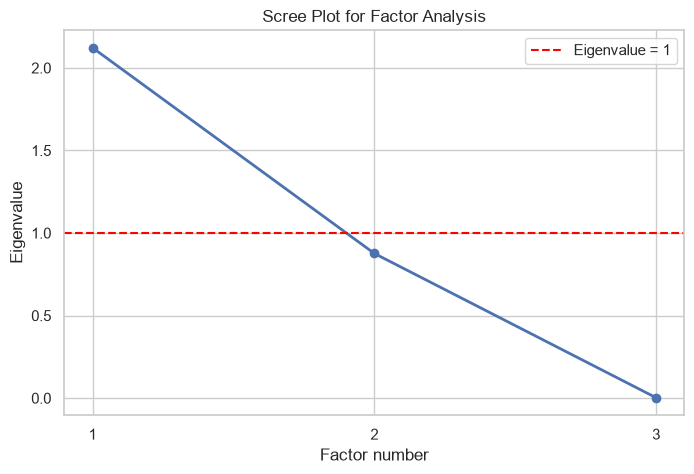

In [12]:
# Scree plot

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker="o",linewidth=2)
plt.axhline(y=1, color="red", linestyle="--", label="Eigenvalue = 1")
plt.xlabel("Factor number")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot for Factor Analysis")
plt.xticks(range(1, len(eigenvalues) + 1))
plt.legend()
plt.grid(True)
plt.show()

**The scree plot**(График осыпей) показывает вклад каждого последующего фактора.

Фактор с относительно большим собственным значением объясняет больше вариаций, чем фактор с меньшим собственным значением.

Сначала будет выделен один фактор и проанализированы его нагрузки и взаимосвязи.

In [ ]:
**Факторный анализ** (Factor analysis) пытается объяснить корреляции между наблюдаемыми переменными с помощью меньшего числа базовых факторов.
для определения того, имеют ли работа, цена и заработная плата общее экономическое измерение, используется один фактор.

Используется метод извлечения МИНРЕСА без ротации.

In [13]:
# Perform factor analysis

# Create a one-factor model
fa = FactorAnalyzer(n_factors=1, method="minres", rotation=None)

# Fit the model
fa.fit(X_scaled_df)

# Extract factor loadings
loadings = pd.DataFrame(fa.loadings_, index=variables, columns=["Factor 1"])
print("FACTOR LOADINGS")
print(loadings.round(3))

# Extract communalities
communalities = pd.DataFrame({"Variable": variables, "Communality": fa.get_communalities()})

print("\nCOMMUNALITIES")
print(communalities.round(3))

# Variance explained
variance = fa.get_factor_variance()
variance_table = pd.DataFrame(variance, index=["SS Loadings", "Proportion Variance", "Cumulative Variance"], columns=["Factor 1"])
print("\nVARIANCE EXPLAINED")
print(variance_table.round(3))

FACTOR LOADINGS
        Factor 1
Work      -0.990
Price     -0.266
Salary    -1.002

COMMUNALITIES
  Variable  Communality
0     Work        0.979
1    Price        0.071
2   Salary        1.005

VARIANCE EXPLAINED
                     Factor 1
SS Loadings             2.055
Proportion Variance     0.685
Cumulative Variance     0.685


In [ ]:
**Факторные нагрузки** (Factor loadings) показывают, насколько сильно каждая наблюдаемая переменная связана с выделенным фактором.
    - Большая положительная нагрузка указывает на сильную положительную взаимосвязь.
    - Большая отрицательная нагрузка указывает на обратную зависимость.
    - Нагрузка, близкая к нулю, указывает на слабую взаимосвязь.

**Общность** (Communality) указывает на долю дисперсии переменной, объясняемую сохраненным фактором. 
Более высокая общность означает, что этот фактор объясняет большую часть вариаций переменной.

**График загрузки факторов** (A factor loading plot) помогает сравнить вклад работы, цены и заработной платы в извлеченный фактор.

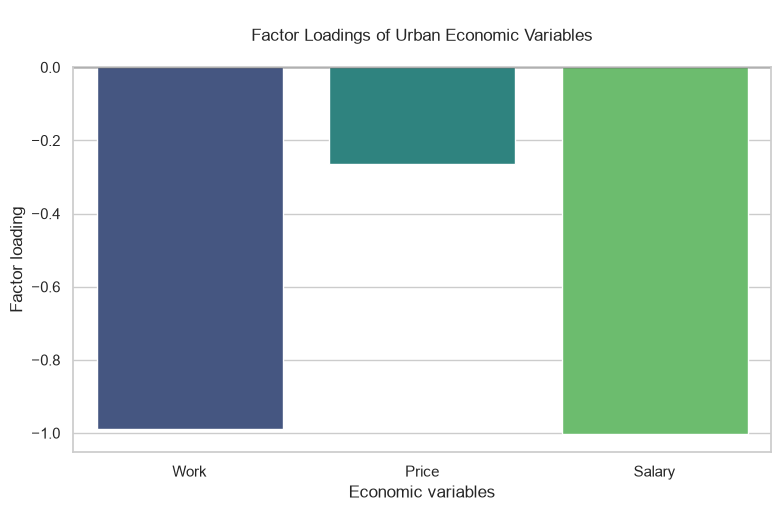

In [14]:
# Visualize factor loadings

plt.figure(figsize=(9, 5))

sns.barplot(x=loadings.index, y=loadings["Factor 1"], hue=loadings.index, palette="viridis", legend=False)
plt.axhline(0, color="black", linewidth=1)
plt.title("\nFactor Loadings of Urban Economic Variables\n")
plt.xlabel("Economic variables")
plt.ylabel("Factor loading")
plt.show()

**Баллы по факторам** (Factor scores) отражают позицию каждого города по выделенному общему фактору.

Их можно использовать для сравнения городов и изучения того, как они различаются в зависимости от базового фактора.

In [15]:
# Calculate factor scores for each city

# Calculate factor scores
factor_scores = fa.transform(X_scaled_df)

# Create a results DataFrame
factor_results = pd.DataFrame({"City": df["City"], "Factor 1 Score": factor_scores[:, 0]})

# Sort cities by factor score
factor_results = factor_results.sort_values(by="Factor 1 Score", ascending=False)
print(factor_results.to_string(index=False))

          City  Factor 1 Score
       Jakarta        4.826199
         Cairo        4.786664
     Hong_Kong        0.298412
        Taipei        0.167380
        Manila        0.082391
         Tokyo        0.013785
   Los_Angeles        0.003968
  Kuala_Lumpur       -0.013857
      Singpore       -0.030250
     Stockholm       -0.037195
       Caracas       -0.042774
      Tel_Aviv       -0.060553
        Bogota       -0.066657
        Panama       -0.080457
       Houston       -0.106006
      New_York       -0.109393
        Geneva       -0.141907
        Zurich       -0.146882
  Buenos_Aires       -0.149627
       Chicago       -0.178738
   Mexico_City       -0.204520
        Bombay       -0.207914
      Helsinki       -0.218071
       Nairobi       -0.219049
  Johannesburg       -0.227984
       Toronto       -0.232853
        Madrid       -0.263493
         Milan       -0.274320
      Montreal       -0.278952
        London       -0.286524
        Vienna       -0.287684
        

**Города с более высокими баллами по факторам** (Cities with higher factor scores) расположены ближе к положительному концу выделенного коэффициента,
в то время как города с более низкими баллами расположены ближе к отрицательному концу.

Экономическое значение этих баллов должно определяться исходя из факторных нагрузок. 
Положительный результат не означает автоматически, что город стал экономически лучше.

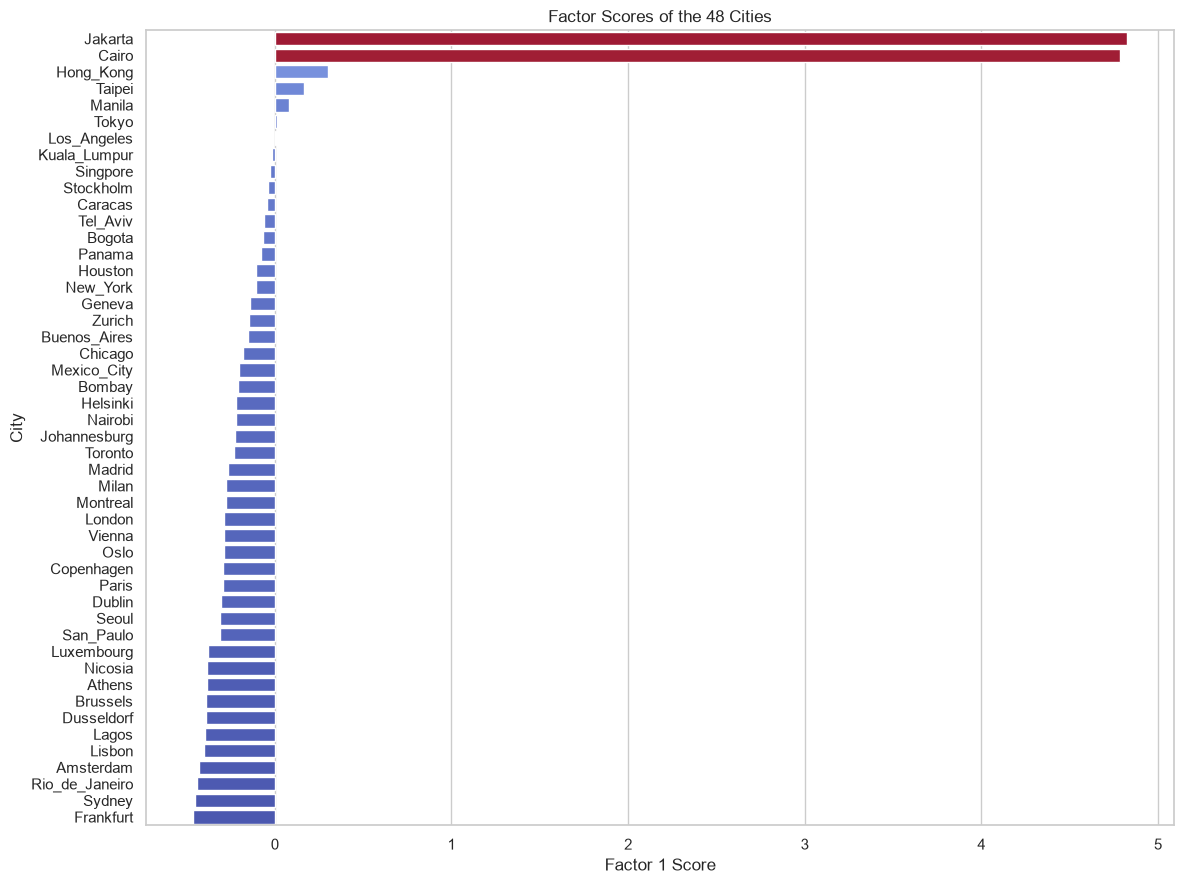

In [16]:
# Visualize factor scores

plt.figure(figsize=(12, 9))

sns.barplot(data=factor_results, x="Factor 1 Score", y="City", hue="Factor 1 Score", palette="coolwarm", legend=False)
plt.title("Factor Scores of the 48 Cities")
plt.xlabel("Factor 1 Score")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [ ]:
**K-Means**(K-средние) - это алгоритм машинного обучения без контроля, используемый для классификации наблюдений по группам в соответствии с их сходством.

Таким образом, каждый город представлен тремя экономическими показателями:
    - Работа
    - Цена
    - Зарплата
Алгоритм группирует города со схожими стандартизированными значениями.

** Основная цель** (The main objective) - выявить экономические сходства и различия между 48 городами.
        
** Основная идея K-Means** (The central idea of K-Means) заключается в том, чтобы привязать каждый город к ближайшему центру кластера
и периодически обновлять эти центры, пока распределение не стабилизируется.
        
**Три выбранных метода** (The three methodological choice) используются для стандартизации экономических переменных для кластеризации.
При этом сохраняется информация по всем трем показателям.

Для расчета K-средних требуется заранее указать количество кластеров (K).

Используются два метода оценки:
**1. Метод Elbow:** (Elbow method) исследуется, как уменьшается вариация внутри кластера с увеличением K.
**2. Silhouette score:** (Оценка силуэта) оценивает, насколько хорошо города вписываются в назначенные им кластеры по сравнению с другими кластерами.
Оценка силуэта варьируется от -1 до +1. Более высокие значения обычно указывают на лучшее разделение.

In [17]:
# K-Means Clustering Analysis
# Determine the optimal number of clusters
# Test different numbers of clusters
inertia_values = []
silhouette_values = []

k_values = range(2, 8)

for k in k_values:

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(X_scaled)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

# Print results
results_k = pd.DataFrame({"Number of clusters": list(k_values), "Inertia": inertia_values, "Silhouette Score": silhouette_values})
print(results_k.round(3))

   Number of clusters  Inertia  Silhouette Score
0                   2   44.598             0.849
1                   3   15.788             0.565
2                   4    5.747             0.619
3                   5    3.742             0.551
4                   6    2.436             0.565
5                   7    1.656             0.540


In [18]:
# K-Means requires the number of clusters (K) to be specified in advance
# Test different numbers of clusters
inertia_values = []
silhouette_values = []

k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(X_scaled)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

# Print results
results_k = pd.DataFrame({"Number of clusters": list(k_values), "Inertia": inertia_values, "Silhouette Score": silhouette_values})
print(results_k.round(3))

   Number of clusters  Inertia  Silhouette Score
0                   2   44.598             0.849
1                   3   15.788             0.565
2                   4    5.747             0.619
3                   5    3.742             0.551
4                   6    2.436             0.565
5                   7    1.656             0.540


## Выбор количества кластеров (Selection of the Number of Clusters)

K-means (K-среднее) значение требует, чтобы количество кластеров, K, было задано перед установкой модели.

Используются два метода оценки:

1. **Метод Elbow:** (The Elbow Method) анализируется сумма квадратов расстояний внутри кластера (инерция). Точка, в которой снижение инерции начинает замедляться, может указывать на подходящее количество кластеров.
3. **The Silhouette Score:** (Оценка силуэта) показывает, насколько каждое наблюдение похоже на свой собственный кластер по сравнению с другими кластерами. Более высокие оценки, как правило, указывают на более четко разделенные кластеры.

Сравнивается несколько значений K. При окончательном выборе учитываются как параметры локтя, так и параметры силуэта.

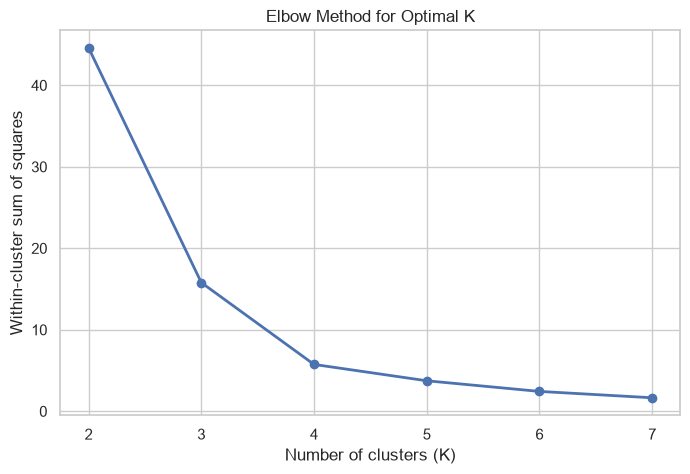

In [19]:
# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o", linewidth=2)
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-cluster sum of squares")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

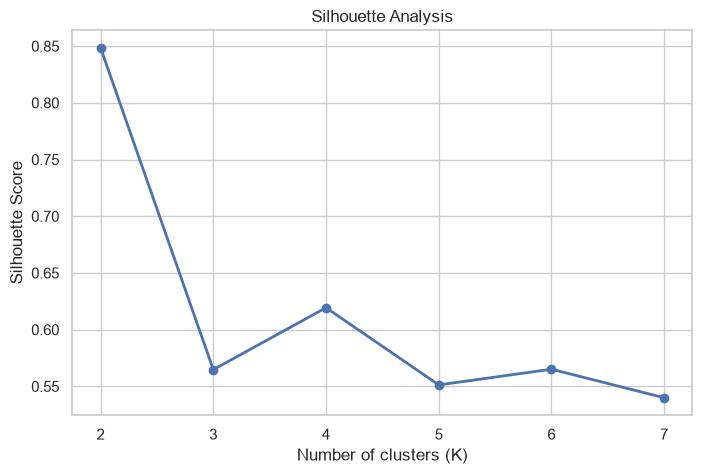

In [20]:
# Silhouette score plot

plt.figure(figsize=(8, 5))
plt.plot( list(k_values), silhouette_values, marker="o", linewidth=2)
plt.title("Silhouette Analysis")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

На графике elbow показано, как уменьшается вариабельность внутри кластера по мере увеличения числа кластеров.

На графике silhouette сравнивается разделение и сплоченность кластеров. 
Более высокий показатель silhouette указывает на более четкие кластеры.
Выбранное количество кластеров основано на наивысшей оценке силуэта среди протестированных значений, а также на графике изгиба.
Этот выбор является скорее решением, основанным на данных, чем предположением о том, что определенное количество кластеров должно быть правильным.

## Кластеризация по K-средним значениям (K-means Clustering)

После выбора количества кластеров итоговая модель по K-средним значениям сопоставляется со стандартизированными экономическими показателями.
Каждый город относится к одному кластеру в соответствии с его расстоянием от центроидов кластера.
Параметр random_state обеспечивает воспроизводимость, в то время как n_init = 20 запускает алгоритм на основе нескольких начальных конфигураций центроида и сохраняет наилучшее решение.

In [21]:
# Perform K-Means clustering

# Select K with the highest silhouette score

optimal_k = list(k_values)[np.argmax(silhouette_values)]
print("Selected number of clusters:", optimal_k)

# Fit final K-Means model
kmeans_final = KMeans( n_clusters=optimal_k, random_state=42, n_init=20)

# Assign cluster labels
df["Cluster"] = kmeans_final.fit_predict(X_scaled) + 1
print("\nCluster assignments:")
print(df[["City", "Work", "Price", "Salary", "Cluster"]].sort_values("Cluster").to_string(index=False))

Selected number of clusters: 2

Cluster assignments:
          City  Work  Price  Salary  Cluster
         Cairo -9999   37.1 -9999.0        1
       Jakarta -9999   43.6 -9999.0        1
        Bogota  2152   37.9    11.5        2
     Amsterdam  1714   65.6    49.0        2
        Bombay  2052   30.3     5.3        2
      Brussels  1708   73.8    50.5        2
  Buenos_Aires  1971   56.1    12.5        2
        Athens  1792   53.8    30.4        2
       Chicago  1924   73.9    61.9        2
    Copenhagen  1717   91.3    62.9        2
        Dublin  1759   76.0    41.4        2
    Dusseldorf  1693   78.5    60.2        2
     Frankfurt  1650   74.5    60.4        2
        Geneva  1880   95.9    90.3        2
      Helsinki  1667  113.6    66.6        2
       Caracas  2041   61.0    10.9        2
     Hong_Kong  2375   63.8    27.8        2
       Houston  1978   71.9    46.3        2
  Johannesburg  1945   51.1    24.0        2
  Kuala_Lumpur  2167   43.5     9.9        2
  

### Профили кластеров (Cluster Profiles)

Профили кластеров рассчитываются с использованием исходных значений работы, цены и заработной платы.

Среднее значение каждой переменной рассчитывается отдельно для каждого кластера.

Это позволяет сравнить экономические характеристики идентифицированных групп в их исходных единицах измерения.

In [22]:
# Analyze the characteristics of each cluster

# Calculate average economic indicators for each cluster
cluster_means = df.groupby("Cluster")[variables].mean()
print("AVERAGE ECONOMIC INDICATORS BY CLUSTER")
print(cluster_means.round(2))

AVERAGE ECONOMIC INDICATORS BY CLUSTER
            Work  Price   Salary
Cluster                         
1       -9999.00  40.35 -9999.00
2        1879.91  70.10    39.55


Кластерные профили показывают средние экономические характеристики каждой группы.

Группы следует сравнивать с использованием всех трех переменных:
- Работа указывает на различия в продолжительности рабочего времени.
- Цена указывает на различия в стоимости товаров и услуг.
- Заработная плата указывает на различия в почасовой оплате.

Кластер с более высокой средней зарплатой и ценой имеет более высокие значения по этим двум индексам. 
Кластер с более низкой средней занятостью имеет меньшее среднее количество рабочих часов.
Метки кластера являются только числовыми идентификаторами. 
Кластер 1 автоматически не является лучшим или худшим по сравнению с кластером 2.

Number of cities in each cluster:
Cluster
1     2
2    46
Name: count, dtype: int64


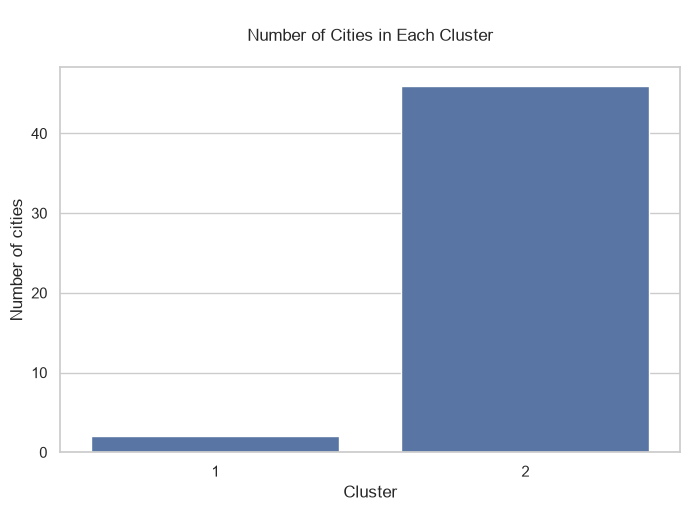

In [23]:
# Number of cities in each cluster
cluster_sizes = df["Cluster"].value_counts().sort_index()
print("Number of cities in each cluster:")
print(cluster_sizes)
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_sizes.index.astype(str), y=cluster_sizes.values)
plt.title("\nNumber of Cities in Each Cluster\n")
plt.xlabel("Cluster")
plt.ylabel("Number of cities")
plt.show()

In [24]:
# Display city membership

for cluster in sorted(df["Cluster"].unique()):
    cities = df.loc[df["Cluster"] == cluster, "City"].tolist()
    print(f"\nCluster {cluster}")
    print("Cities:", ", ".join(cities))


Cluster 1
Cities: Cairo, Jakarta

Cluster 2
Cities: Amsterdam, Athens, Bogota, Bombay, Brussels, Buenos_Aires, Caracas, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Hong_Kong, Houston, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, London, Los_Angeles, Luxembourg, Madrid, Manila, Mexico_City, Milan, Montreal, Nairobi, New_York, Nicosia, Oslo, Panama, Paris, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Stockholm, Sydney, Taipei, Tel_Aviv, Tokyo, Toronto, Vienna, Zurich


### Визуализация кластеров K-средних значений (Visualization of K-means Clusters)

Для отображения результирующих групп используются точечные диаграммы.
Каждая точка представляет один город. Разные цвета представляют разные кластеры K-средних значений.
Графики позволяют визуально сравнивать города в зависимости от цен, заработной платы и работы.

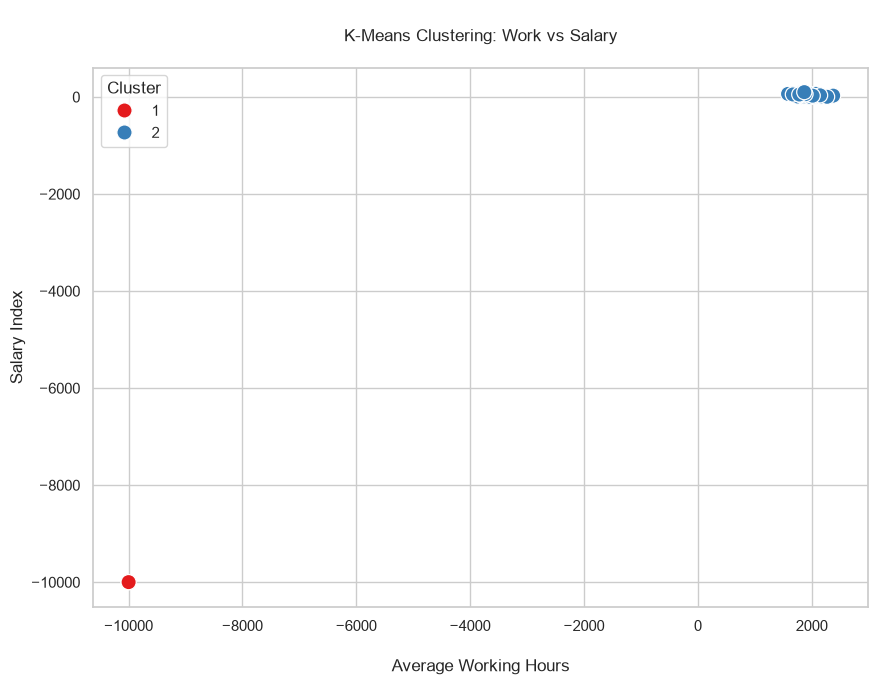

In [25]:
# Visualize the clusters
# Work versus Salary

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x="Work", y="Salary", hue="Cluster", palette="Set1", s=120)
plt.title("\nK-Means Clustering: Work vs Salary\n")
plt.xlabel("\nAverage Working Hours")
plt.ylabel("Salary Index")
plt.legend(title="Cluster")
plt.show()

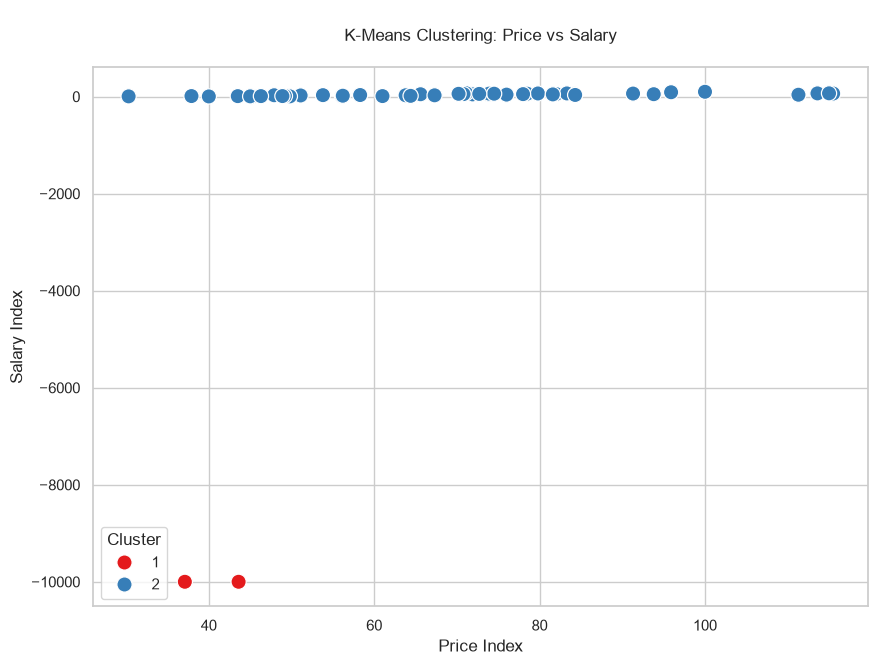

In [26]:
# Price versus Salary

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x="Price", y="Salary", hue="Cluster", palette="Set1", s=120)
plt.title("\nK-Means Clustering: Price vs Salary\n")
plt.xlabel("Price Index")
plt.ylabel("Salary Index")
plt.legend(title="Cluster")
plt.show()

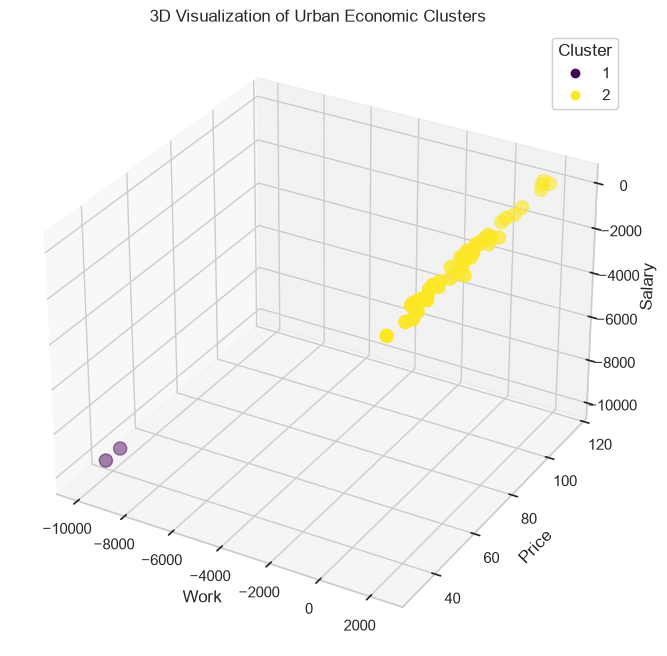

In [27]:
# Three-dimensional cluster visualization

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(df["Work"], df["Price"], df["Salary"], c=df["Cluster"], cmap="viridis", s=90)
ax.set_xlabel("Work")
ax.set_ylabel("Price")
ax.set_zlabel("Salary")

ax.set_title("3D Visualization of Urban Economic Clusters")
legend = ax.legend(*scatter.legend_elements(),
                   title="Cluster")

ax.add_artist(legend)
plt.show()

Точечные диаграммы дают наглядное представление о классификации по K-средним значениям.

Города, расположенные близко друг к другу на графиках, имеют схожие значения для показанных переменных. Цвета указывают на распределение по кластерам.

График "Цена-зарплата" особенно полезен для сравнения взаимосвязи между индексом затрат и заработной платы. На других графиках показано, как различается продолжительность рабочего дня в разных группах.

Точечные графики показывают только две переменные одновременно, в то время как модель K-средних использует все три стандартизированные переменные.

### Центроиды кластеров (Cluster Centroids)

Центроид представляет центр каждого кластера в пространстве стандартизированных переменных.

Стандартизированные центроиды показывают, находится ли кластер выше или ниже общего среднего значения по каждой переменной.

Положительные значения центроида указывают на стандартизированные значения выше среднего, в то время как отрицательные значения указывают на стандартизированные значения ниже среднего.

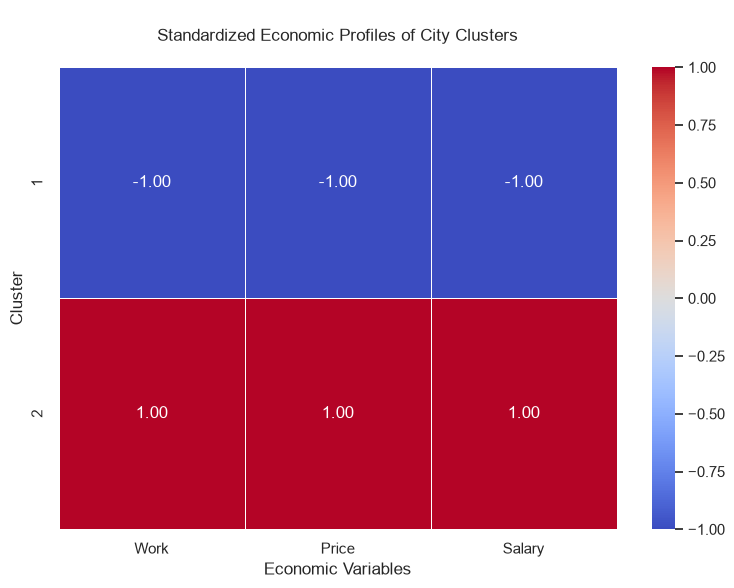

In [28]:
# Compare clusters using a heatmap

# Standardize cluster averages for visualization
cluster_means_scaled = pd.DataFrame(
    StandardScaler().fit_transform(cluster_means),
    index=cluster_means.index,
    columns=cluster_means.columns
)

plt.figure(figsize=(9, 6))
sns.heatmap(cluster_means_scaled, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("\nStandardized Economic Profiles of City Clusters\n")
plt.xlabel("Economic Variables")
plt.ylabel("Cluster")
plt.show()

Тепловая карта центроида сравнивает экономические характеристики каждого кластера с общими стандартизированными средними показателями.

Положительные значения указывают на то, что кластер имеет значение соответствующего показателя выше среднего. Отрицательные значения указывают на значения ниже среднего.

Тепловая карта помогает определить, какие показатели наиболее четко выделяют кластеры.

### Оценка результатов кластеризации (Evaluation of the Clustering Result)

Итоговый балл silhouette рассчитывается для оценки того, насколько хорошо города разделены на кластеры.

Оценка интерпретируется следующим образом:

- Близко к +1: наблюдения хорошо соответствуют их собственным кластерам и отделены от других кластеров.
- Около 0: кластеры перекрываются или наблюдения находятся вблизи границ кластеров.
- Ниже 0: некоторые наблюдения могут быть отнесены к неподходящему кластеру.

Оценка является оценочным показателем, а не доказательством того, что кластеры представляют объективно установленные экономические категории.

In [29]:
# Combine factor analysis and K-Means results

# Add factor scores to the original dataset
df["Factor 1 Score"] = factor_scores[:, 0]

# Create a combined results table
final_results = df[
    ["City", "Work", "Price", "Salary",
     "Factor 1 Score", "Cluster"]
].sort_values("Cluster")

print(final_results.to_string(index=False))

          City  Work  Price  Salary  Factor 1 Score  Cluster
         Cairo -9999   37.1 -9999.0        4.786664        1
       Jakarta -9999   43.6 -9999.0        4.826199        1
        Bogota  2152   37.9    11.5       -0.066657        2
     Amsterdam  1714   65.6    49.0       -0.429001        2
        Bombay  2052   30.3     5.3       -0.207914        2
      Brussels  1708   73.8    50.5       -0.388146        2
  Buenos_Aires  1971   56.1    12.5       -0.149627        2
        Athens  1792   53.8    30.4       -0.385114        2
       Chicago  1924   73.9    61.9       -0.178738        2
    Copenhagen  1717   91.3    62.9       -0.294139        2
        Dublin  1759   76.0    41.4       -0.304568        2
    Dusseldorf  1693   78.5    60.2       -0.392652        2
     Frankfurt  1650   74.5    60.4       -0.462925        2
        Geneva  1880   95.9    90.3       -0.141907        2
      Helsinki  1667  113.6    66.6       -0.218071        2
       Caracas  2041   6

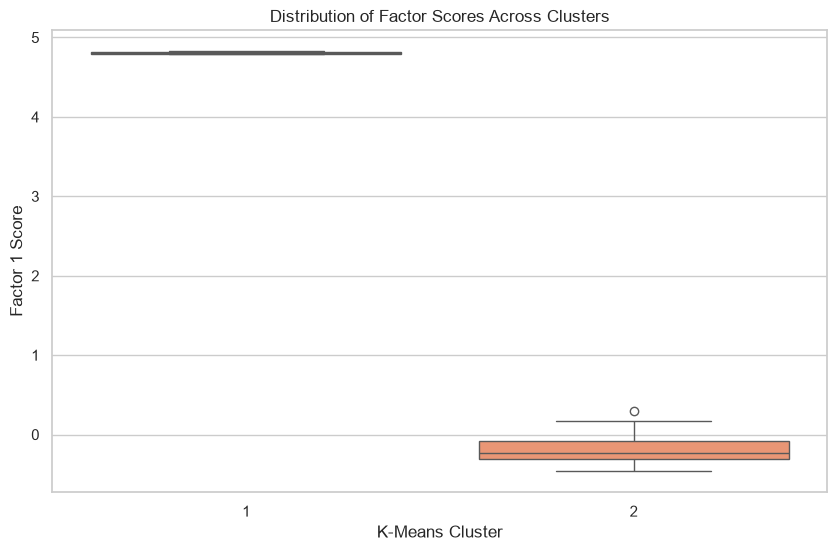

In [30]:
# Factor scores by cluster
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Cluster",
    y="Factor 1 Score",
    hue="Cluster",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Factor Scores Across Clusters")
plt.xlabel("K-Means Cluster")
plt.ylabel("Factor 1 Score")

plt.show()

# Заключение

В ходе анализа были проанализированы экономические условия в 48 городах мира в 1991 году с использованием метода кластеризации K-средних.
Анализ был сосредоточен на трех экономических показателях: продолжительности рабочего времени (Work), индексе цен (Price) и индексе заработной платы (Salary).
Значение -9999 было учтено как пропущенное значение. Следовательно, в кластерный анализ были включены 46 городов с полными наблюдениями.

Описательная статистика показала различия в продолжительности рабочего дня, ценах и заработной плате между городами. Корреляционный анализ показал сильную положительную взаимосвязь между ценой и заработной платой (0,804). Работа имела отрицательную корреляцию с ценой (-0,452) и зарплатой (-0,457).

Перед кластеризацией все три числовые переменные были стандартизированы с помощью StandardScaler. Этот шаг был необходим, поскольку показатели имеют разные шкалы измерения.

Количество кластеров, исследованных с использованием метода Elbow, и оценка силуэта. Среди протестированных значений от K = 2 до K = 7, значение K = 2 дало наивысшую оценку силуэта, равную приблизительно 0,4705. Таким образом, были выбраны два кластера.

Первый кластер содержал 21 город. Для него характерны более высокая средняя продолжительность рабочего дня (1 987,86 часов), более низкий средний индекс цен (52,40) и более низкий индекс средней заработной платы (16,35).

Во второй кластер вошли 25 городов. У него была более низкая средняя продолжительность рабочего дня (1789,24 часа), более высокий средний индекс цен (84,97) и более высокий индекс средней заработной платы (59,03).

Результаты показывают, что города можно разделить на две группы с различными экономическими характеристиками. В первой группе относительно больше продолжительности рабочего дня и более низкие показатели цен и заработной платы, в то время как во второй группе относительно меньше продолжительности рабочего дня и более высокие показатели цен и заработной платы.

Гипотеза о том, что города можно сгруппировать по сходству часов работы, цен и зарплат, подтверждается результатами кластеризации.

В заключение следует отметить, что кластеризация с использованием K-средних обеспечила полезный способ выявления и визуализации сходств и различий в экономических условиях городов в 1991 году.